# Proposal Figures

Read-only code for Figures 1–3 (saved to `proposal/`). It fits no models and never uses the test set; Figure 3 reads stored preliminary validation results.

In [1]:
# Step 1: Setup — Read-Only Access to the Project's Data Loaders and Stored Results
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path('src/core').resolve()))
import masking
import model_utils as mu

OUT = Path('proposal')
OUT.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GRAY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984', '#0b0b0b'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9,
                     'axes.titleweight': 'bold', 'axes.titlesize': 9.5})

split = mu.read_split()
data = mu.read_data().set_index('Incident_ID').loc[split.Incident_ID].assign(split=split.set_index('Incident_ID')['split'])
train = data.loc[data['split'] == 'train']

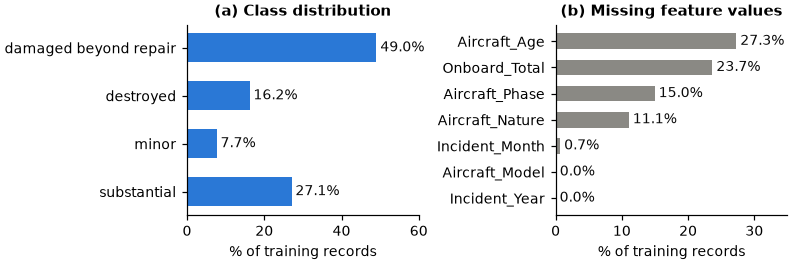

In [2]:
# Step 2: Figure 1 — Class Imbalance and Feature Missingness (Training Set)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4), layout='constrained')
share = train[mu.TARGET].value_counts(normalize=True).reindex(mu.CLASSES)*100
axes[0].barh(mu.CLASSES[::-1], share[::-1], color=BLUE, height=.6)
for y, v in enumerate(share[::-1]):
    axes[0].text(v+1, y, f'{v:.1f}%', va='center', color=INK)
axes[0].set(title='(a) Class distribution', xlabel='% of training records', xlim=(0, 60))
missing = (train[mu.FEATURES].isna().mean()*100).sort_values()
axes[1].barh(missing.index, missing.values, color=GRAY, height=.6)
for y, v in enumerate(missing.values):
    axes[1].text(v+.6, y, f'{v:.1f}%', va='center', color=INK)
axes[1].set(title='(b) Missing feature values', xlabel='% of training records', xlim=(0, 35))
fig.savefig(OUT/'fig1_data.png', dpi=200, facecolor='white')
plt.show()

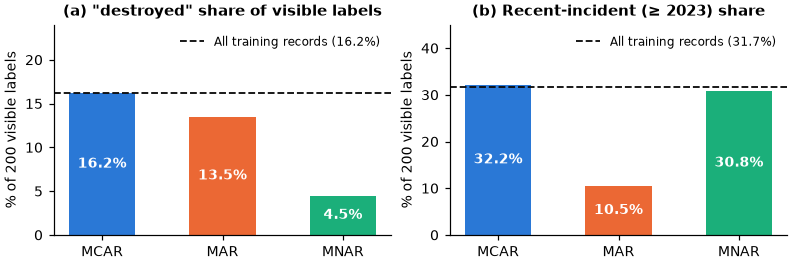

In [3]:
# Step 3: Figure 2 — The Simulated Mechanisms Change Who Gets a Label (200 Visible Labels, 5 Seeds)
X = mu.training_features()
y = mu.read_data().set_index('Incident_ID').loc[X.index, mu.TARGET]
recent = X.Incident_Year.fillna(-1).to_numpy() >= 2023
rows = []
for mechanism in ['MCAR', 'MAR', 'MNAR']:
    for seed in range(42, 47):
        visible = masking.make_mask(X, 200, seed, mechanism, outcomes=y).is_labeled.to_numpy()
        rows.append(dict(mechanism=mechanism, destroyed=(y[visible] == 'destroyed').mean()*100,
                         recent=recent[visible].mean()*100))
shares = pd.DataFrame(rows).groupby('mechanism', sort=False).mean()
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4), layout='constrained')
for ax, column, population, title in [
        (axes[0], 'destroyed', (y == 'destroyed').mean()*100, '(a) "destroyed" share of visible labels'),
        (axes[1], 'recent', recent.mean()*100, '(b) Recent-incident (≥ 2023) share')]:
    ax.bar(shares.index, shares[column], color=[BLUE, ORANGE, AQUA], width=.55)
    ax.axhline(population, color=INK, linestyle='--', linewidth=1.2, label=f'All training records ({population:.1f}%)')
    for x, v in enumerate(shares[column]):
        ax.text(x, v/2, f'{v:.1f}%', ha='center', va='center', color='white', fontweight='bold')
    ax.set(title=title, ylabel='% of 200 visible labels')
    ax.legend(frameon=False, loc='upper right', fontsize=8)
axes[0].set_ylim(0, 24)
axes[1].set_ylim(0, 45)
fig.savefig(OUT/'fig2_mechanisms.png', dpi=200, facecolor='white')
plt.show()

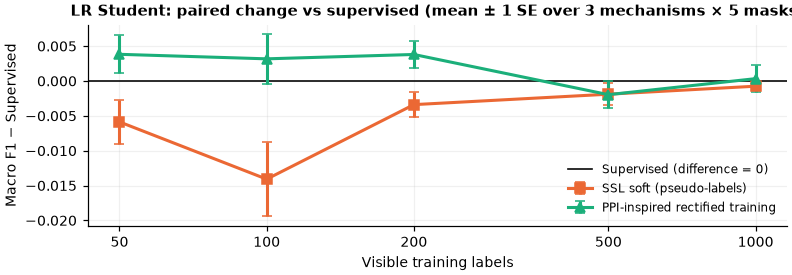

In [4]:
# Step 4: Figure 3 — Quick Preliminary Result (LR Student, Validation, CatBoost Teacher)
db = sqlite3.connect(f'file:{mu.DB_PATH}?mode=ro', uri=True)
metrics = pd.read_sql_query("SELECT mechanism,budget,seed,method,macro_f1 FROM metrics WHERE method LIKE 'LR / %'", db)
db.close()
wide = metrics.pivot_table(index=['mechanism', 'budget', 'seed'], columns='method', values='macro_f1')
budgets = [50, 100, 200, 500, 1000]
fig, ax = plt.subplots(figsize=(7.2, 2.5), layout='constrained')
ax.axhline(0, color=INK, linewidth=1.1, label='Supervised (difference = 0)')
for method, color, marker, label in [('LR / SSL soft', ORANGE, 's', 'SSL soft (pseudo-labels)'),
                                     ('LR / PPI selected', AQUA, '^', 'PPI-inspired rectified training')]:
    d = (wide[method]-wide['LR / Supervised']).groupby(level='budget')
    mean, se = d.mean().reindex(budgets), (d.std()/np.sqrt(d.count())).reindex(budgets)
    ax.errorbar(budgets, mean, yerr=se, color=color, marker=marker, linewidth=2, markersize=6, capsize=3, label=label)
ax.set_xscale('log')
ax.set_xticks(budgets, [str(b) for b in budgets])
ax.minorticks_off()
ax.grid(alpha=.18)
ax.set(xlabel='Visible training labels', ylabel='Macro F1 − Supervised',
       title='LR Student: paired change vs supervised (mean ± 1 SE over 3 mechanisms × 5 masks)')
ax.legend(frameon=False, loc='lower right', fontsize=8)
fig.savefig(OUT/'fig3_preliminary.png', dpi=200, facecolor='white')
plt.show()